# **Superstore Sales Demand Forecasting**

## Dataset

Retail operations di Amerika Serikat periode 2011 sampai 2014, terdiri dari 3 file:

| File | Isi |
|---|---|
|`superstore-orders-data.csv`|21 kolom: detail order, customer, sales, profit, shipping, produk, kategori produk|
|`superstore-returns-data.csv`|Pemetaan `Order ID` yang direturn|
|`superstore-people-data.csv`|Regional manager per `Region` (West, East, Central, South|

## Decision Design
|Keputusan|Pilihan|Alasan|
|---|---|---|
|Variabel target|`Sales` (nilai penjualan)|Permintaan penjualan diukur dalam nilai transaksi|
|Level agregasi|`Region` x `Category` per bulan|Total bulanan hanya 48 titik, terlalu sedikit untuk model berbasis fitur. Level ini menghasilkan 12 deret waktu dan sekitar 570 baris, sekaligus memanfaatkan tabel `People` (manajer regional)|
|Pembagian data|Berurutan waktu|Pembagian acak membuat model memakai informasi masa depan|
|Fitur|Lag dan rata-rata bergulir dari `Sales` bulan sebelumnya, serta kalender|`Quantity`, `Discount`, `Profit` bulan yang sama belum diketahui saat peramalan dibuat, sehingga tidak boleh dipakai langsung|



### Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
orders = pd.read_csv("../data/raw/superstore-orders-data.csv")
people = pd.read_csv("../data/raw/superstore-people-data.csv")
returns = pd.read_csv("../data/raw/superstore-returns-data.csv")

In [3]:
print("Orders :", orders.shape)
print("People :", people.shape)
print("Returns :", returns.shape)

Orders : (9994, 21)
People : (4, 2)
Returns : (296, 2)


# Data Wrangling
**Tujuan**: memastikan data bersih, tipe data benar, dan ketiga tabel tergabung dengan benar.

### Understanding the data

In [4]:
orders.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,11/9/2013,11/12/2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,11/9/2013,11/12/2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,6/13/2013,6/17/2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,10/11/2012,10/18/2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,10/11/2012,10/18/2012,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

Pada data orders disini, terdapat beberapa kolom yang belum rapi (masih ada jarak), dan tipe data yang kurang sesuai, seperti Order Date yang seharusnya datetime. Barisnya sudah bersih, alias tidak ada baris kosong.

In [6]:
orders.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [7]:
print("Nilai kosong per kolom:")
print(orders.isnull().sum())
print()
print("Baris duplikat:")
print(orders.duplicated().sum())

Nilai kosong per kolom:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Baris duplikat:
0


In [8]:
print(people.head())
print()
print(returns.head())

              Person   Region
0      Anna Andreadi     West
1        Chuck Magee     East
2     Kelly Williams  Central
3  Cassandra Brandow    South

  Returned        Order ID
0      Yes  CA-2014-153822
1      Yes  CA-2014-129707
2      Yes  CA-2011-152345
3      Yes  CA-2012-156440
4      Yes  US-2014-155999


### Formatting Column Names

Spasi dan tanda hubung pada nama kolom menyulitkan pemanggilan kolom di kode. Semua nama diseragamkan menjadi huruf dengan garis bawah, misalnya `Sub-Category` menjadi `Sub_Category`.

In [9]:
for df_ in (orders, people, returns):
    df_.columns = (df_.columns.str.strip()
                   .str.replace(" ", "_")
                   .str.replace("-", "_"))

In [10]:
required_column = ["Order_ID", "Order_Date", "Region", "Category", "Sub_Category", "Quantity",
                   "Sales", "Discount", "Profit"]

In [11]:
print("Kolom wajib yang tidak ditemukan:", [c for c in required_column if c not in orders.columns])
print()
print("Orders column :", list(orders.columns))
print("People column :", list(people.columns))
print("Returns column:", list(returns.columns))

Kolom wajib yang tidak ditemukan: []

Orders column : ['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit']
People column : ['Person', 'Region']
Returns column: ['Returned', 'Order_ID']


### Changing the date types

Setelah konversi, nilai minimum dan maksimum `Order_Date` harus berada pada rentang 2011 sampai 2014 sesuai deskripsi dataset.

In [12]:
orders["Order_Date"] = pd.to_datetime(orders["Order_Date"])
orders["Ship_Date"] = pd.to_datetime(orders["Ship_Date"])

print("Tanggal pesanan paling awal  :", orders["Order_Date"].min())
print("Tanggal pesanan paling akhir :", orders["Order_Date"].max())

Tanggal pesanan paling awal  : 2011-01-04 00:00:00
Tanggal pesanan paling akhir : 2014-12-31 00:00:00


#### Merging tables

Tabel `Returns` dipetakan ke `Orders` melalui `Order_ID`, sedangkan tabel `People` melalui `Region`. Jumlah baris sebelum dan sesudah penggabungan harus sama. Jika berbeda, terdapat kunci ganda yang perlu di telusuri.

In [13]:
# Hapus duplikat Order_ID pada dataset returns
returns = returns.drop_duplicates(subset="Order_ID")
n_awal = len(orders)

In [14]:
# Gabungkan hasil returns terbaru dengan dataset orders
orders = orders.merge(returns, on="Order_ID", how="left")

In [15]:
# Ubah Status returns yang tidak ada pada dataset orders menjadi "No"
orders["Returned"] = orders["Returned"].fillna("No")

In [16]:
# Gabungkan dataset people dengan orders
orders = orders.merge(people, on="Region", how="left")

In [17]:
# Mengecek baris dataset orders sebelum dan sesudah merge
print("Baris sebelum:", n_awal, "| sesudah:", len(orders))
# Periksa kunci penggabungan
assert n_awal == len(orders), "Jumlah baris berubah, periksa kunci penggabungan"

Baris sebelum: 9994 | sesudah: 9994


In [18]:
orders["Returned"].value_counts()

Returned
No     9194
Yes     800
Name: count, dtype: int64

### Create calendar features

In [19]:
orders["Year"] = orders["Order_Date"].dt.year
orders["Month"] = orders["Order_Date"].dt.month
orders["Year_Month"] = orders["Order_Date"].dt.to_period("M").dt.to_timestamp()

orders[["Order_Date", "Year", "Month", "Year_Month"]].head()

,Order_Date,Year,Month,Year_Month
0,2013-11-09,2013,11,2013-11-01
1,2013-11-09,2013,11,2013-11-01
2,2013-06-13,2013,6,2013-06-01
3,2012-10-11,2012,10,2012-10-01
4,2012-10-11,2012,10,2012-10-01


### Decisions on Handling Returns

Penjualan pada analisis ini didefinisikan sebagai nilai pesanan yang masuk, sehingga pesanan retur tetap dihitung (`include_returns = True`), yang disebut juga penjualan kotor. Ubah menjadi `False` untuk menghitung penjualan bersih dan bandingkan hasil akhirnya.

In [20]:
include_returns = True

if include_returns:
    demand_src = orders.copy()
else:
    demand_src = orders[orders["Returned"] == "No"].copy()

print("Baris yang dipakai:", len(demand_src))
print("Total Sales       :", round(demand_src["Sales"].sum(), 2))

Baris yang dipakai: 9994
Total Sales       : 2297200.86


### Task

1. Periksa apakah ada nilai `Sales` nol atau negatif, lalu tentukan cara penanganannya dan tulis alasannya.
2. Hitung persentase nilai `Sales` yang berstatus `Returned = Yes` terhadap total `Sales`, dan bandingkan dengan persentase jumlah pesanannya.
3. Buat kolom `Lead_Days` (selisih `Ship_Date` dan `Order_Date`) dan periksa apakah ada nilai yang tidak masuk akal.
4. Ubah tipe `Category`, `Region`, dan `Segment` menjadi `category`, lalu bandingkan penggunaan memori dengan `orders.info(memory_usage='deep')` sebelum dan sesudahnya.

In [29]:
# Nilai Sales nol atau negatif

print("Sales <= 0:", (orders["Sales"] <= 0).sum())
print("Sales negatif:", (orders["Sales"] < 0).sum())

print(orders["Sales"].describe())

Sales <= 0: 0
Sales negatif: 0
count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64


**Catatan:** jika jumlahnya nol, tidak ada penanganan khusus yang diperlukan. Jika ada, periksa dahulu barisnya dengan `orders[orders["Sales"] <= 0]`. Nilai nol dapat berupa transaksi sah (misalnya barang promosi gratis) sehingga tidak otomatis dihapus. Nilai negatif biasanya menandakan koreksi atau retur yang tercatat sebagai baris tersendiri. Apa pun keputusannya, tulis alasannya pada catatan analisis.

In [31]:
# Persentase retur menurut nilai dan menurut jumlah pesanan

pct_nilai = 100 * orders.loc[orders["Returned"] == "Yes", "Sales"].sum() / orders["Sales"].sum()

n_pesanan = orders["Order_ID"].nunique()
n_retur = orders.loc[orders["Returned"] == "Yes", "Order_ID"].nunique()
pct_pesanan = 100 * n_retur / n_pesanan

print(f"Retur menurut nilai Sales    : {pct_nilai:.2f}%")
print(f"Retur menurut jumlah pesanan : {pct_pesanan:.2f}% ({n_retur} dari {n_pesanan} pesanan)" )

Retur menurut nilai Sales    : 7.86%
Retur menurut jumlah pesanan : 5.91% (296 dari 5009 pesanan)


**Catatan:** jika persentase menurut nilai lebih besar daripada menurut jumlah pesanan, pesanan yang diretur cenderung bernilai di atas rata-rata. Jika lebih kecil, retur lebih banyak terjadi pada pesanan bernilai kecil. Selisih keduanya menentukan seberapa besar perbedaan antara penjualan kotor dan penjualan bersih.

In [33]:
# Lead_Days column

orders["Lead_Days"] = (orders["Ship_Date"] - orders["Order_Date"]).dt.days

In [34]:
print(orders["Lead_Days"].describe())

count    9994.000000
mean        3.958875
std         1.747097
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Lead_Days, dtype: float64


In [36]:
print("Lead_Days negatif:", (orders["Lead_Days"] < 0).sum())
print("Lead_Days di atas 14 hari:", (orders["Lead_Days"] > 14).sum())

Lead_Days negatif: 0
Lead_Days di atas 14 hari: 0


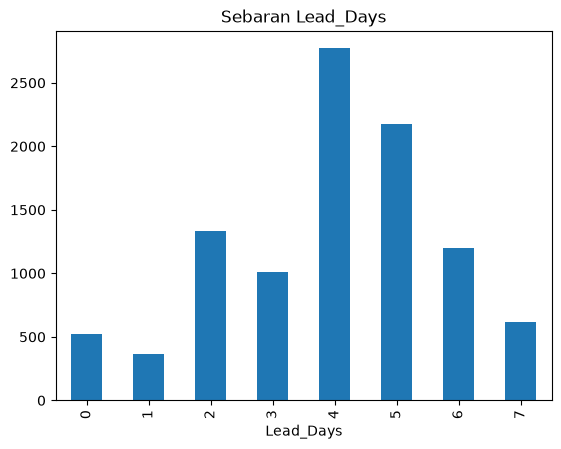

In [37]:
# Buat plot sebaran
orders["Lead_Days"].value_counts().sort_index().plot(kind="bar", title="Sebaran Lead_Days")

plt.show()

**Catatan:** nilai negatif tidak masuk akal karena pengiriman tidak mungkin mendahului pemesanan, sehingga baris tersebut perlu diperiksa. Nilai yang sangat besar juga perlu dicek terhadap `Ship_Mode`.

In [48]:
# Tipe data category dan penggunaan memori
sebelum = orders.memory_usage(deep=True).sum() / 1024**2

In [49]:
tmp = orders.copy()
for kol in ["Category", "Region", "Segment"]:
    tmp[kol] = tmp[kol].astype("category")

In [52]:
sesudah = tmp.memory_usage(deep=True).sum() / 1024**2

print(f"Sebelum: {sebelum:.2f} MB")
print(f"Sesudah: {sesudah:.2f} MB")
print(f"Penghematan: {100 * (1 - sesudah / sebelum):.1f}%")

Sebelum: 9.58 MB
Sesudah: 7.95 MB
Penghematan: 17.0%


**Catatan:** kolom teks dengan sedikit nilai unik sangat efisien jika disimpan sebagai `category` karena nilainya disimpan sekali dan baris hanya menyimpan kode. Pada dataset sekecil ini penghematan belum terasa penting, tetapi kebiasaan ini berguna pada data berukuran besar.